In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from mpl_toolkits.mplot3d import Axes3D
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report
import numpy as np

In [2]:
iris = pd.read_csv('/content/Iris.csv')
iris.drop(columns=["Id"], inplace=True)
iris.head(15)

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa
5,5.4,3.9,1.7,0.4,Iris-setosa
6,4.6,3.4,1.4,0.3,Iris-setosa
7,5.0,3.4,1.5,0.2,Iris-setosa
8,4.4,2.9,1.4,0.2,Iris-setosa
9,4.9,3.1,1.5,0.1,Iris-setosa


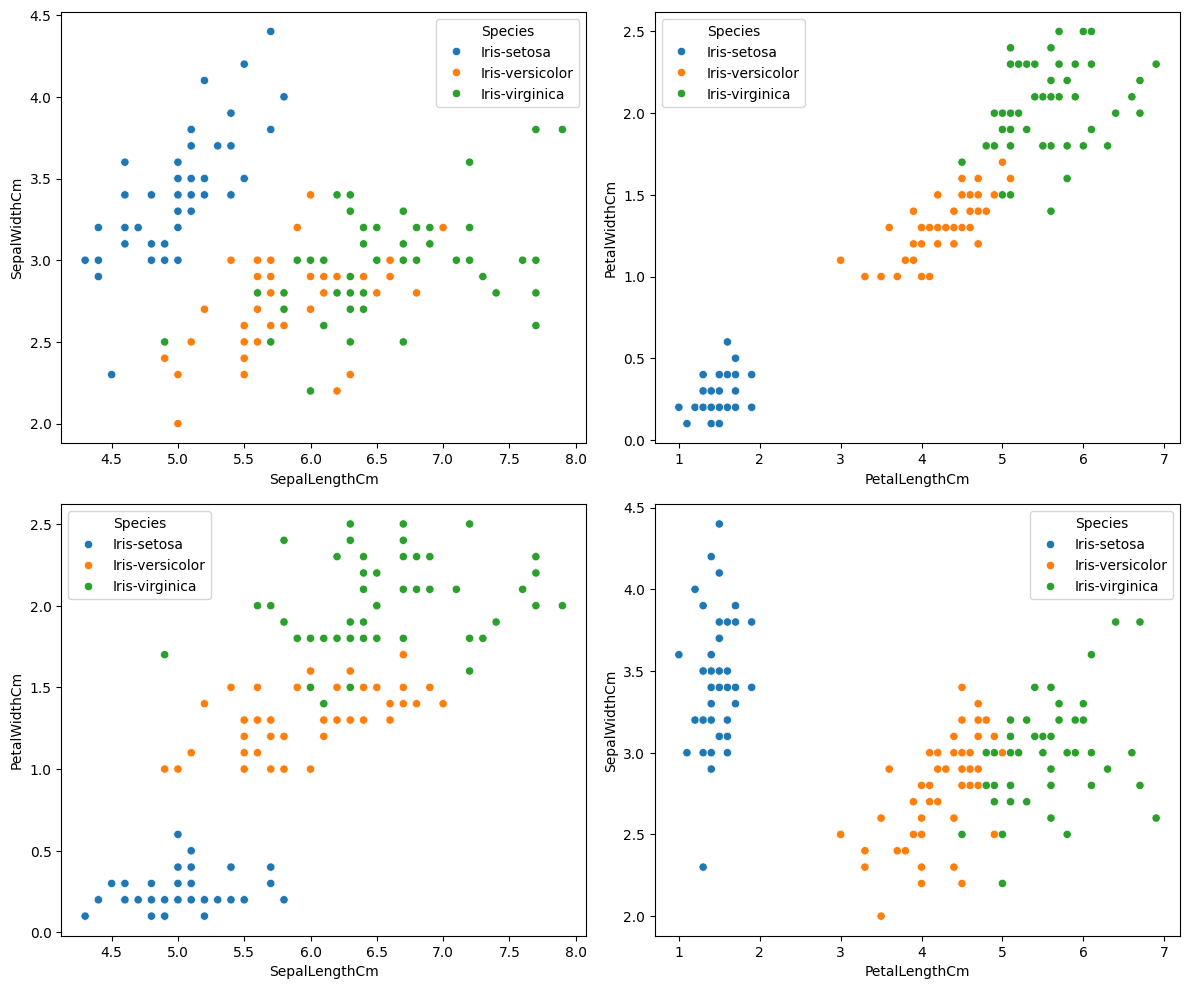

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

sns.scatterplot(data=iris, x='SepalLengthCm', y='SepalWidthCm', hue='Species', ax=axes[0, 0])
sns.scatterplot(data=iris, x='PetalLengthCm', y='PetalWidthCm', hue='Species', ax=axes[0, 1])
sns.scatterplot(data=iris, x='SepalLengthCm', y='PetalWidthCm', hue='Species', ax=axes[1, 0])
sns.scatterplot(data=iris, x='PetalLengthCm', y='SepalWidthCm', hue='Species', ax=axes[1, 1])

plt.tight_layout()
plt.show()

In [4]:
iris.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   SepalLengthCm  150 non-null    float64
 1   SepalWidthCm   150 non-null    float64
 2   PetalLengthCm  150 non-null    float64
 3   PetalWidthCm   150 non-null    float64
 4   Species        150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [5]:
iris.describe()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


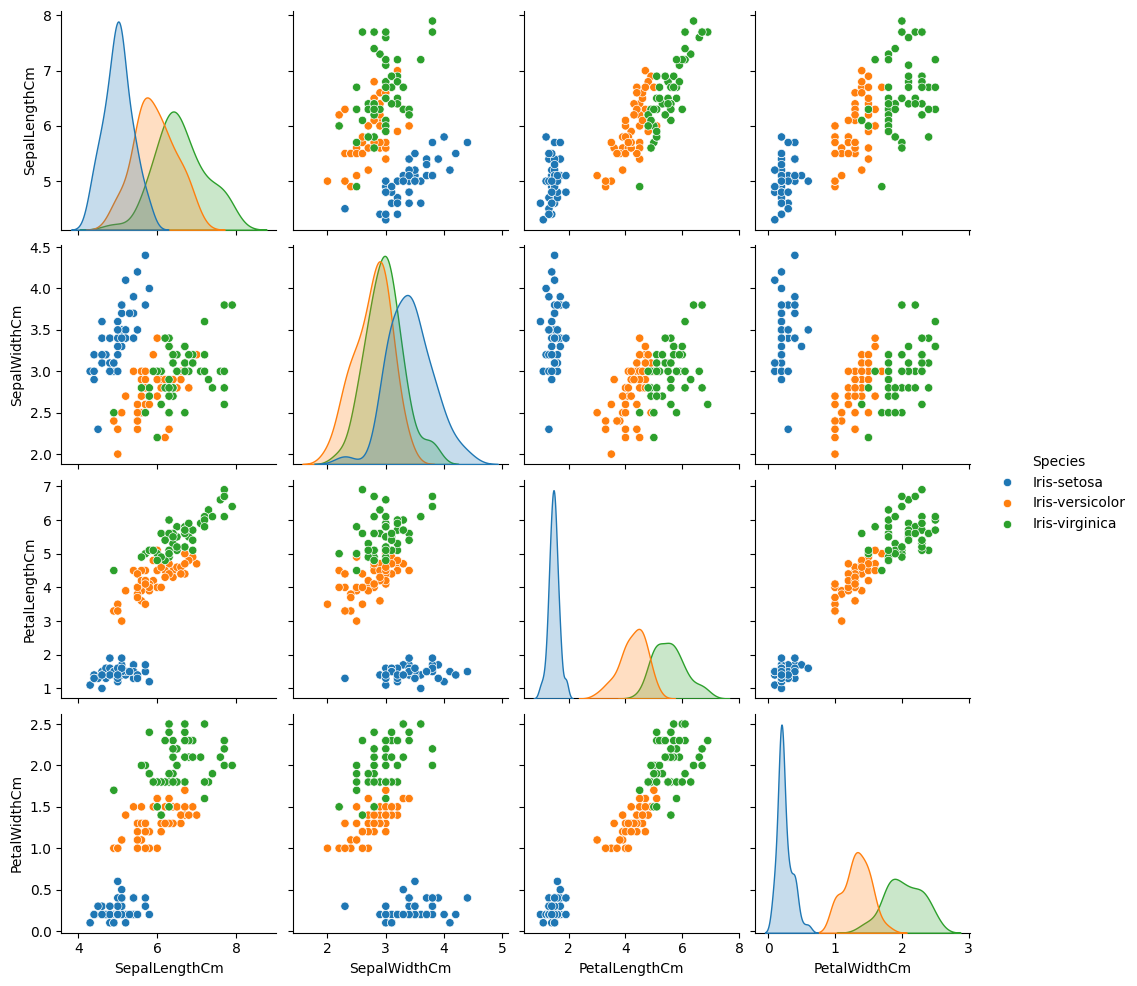

In [7]:
sns.pairplot(iris, hue='Species')

               SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
SepalLengthCm       1.000000     -0.109369       0.871754      0.817954
SepalWidthCm       -0.109369      1.000000      -0.420516     -0.356544
PetalLengthCm       0.871754     -0.420516       1.000000      0.962757
PetalWidthCm        0.817954     -0.356544       0.962757      1.000000


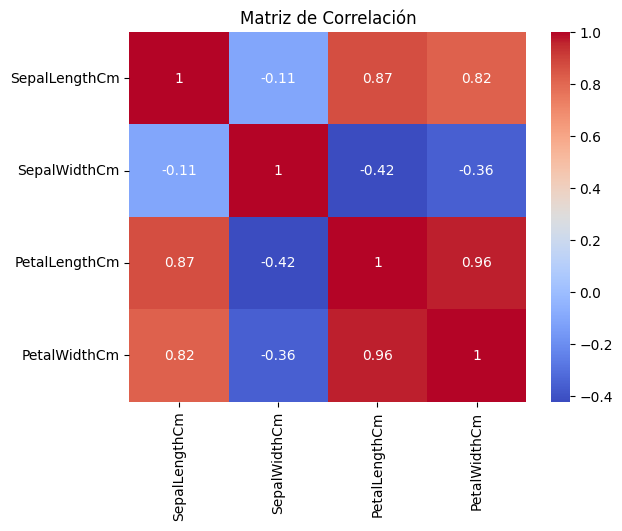

In [8]:
iris_numeric = iris[['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']]

corr_matrix = iris_numeric.corr()

print(corr_matrix)

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title('Matriz de Correlación')
plt.show()

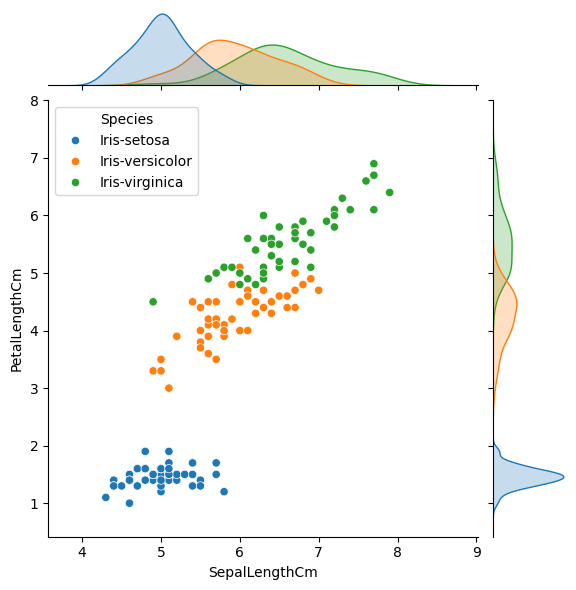

In [9]:
sns.jointplot(data=iris, x = 'SepalLengthCm', y='PetalLengthCm', hue='Species')

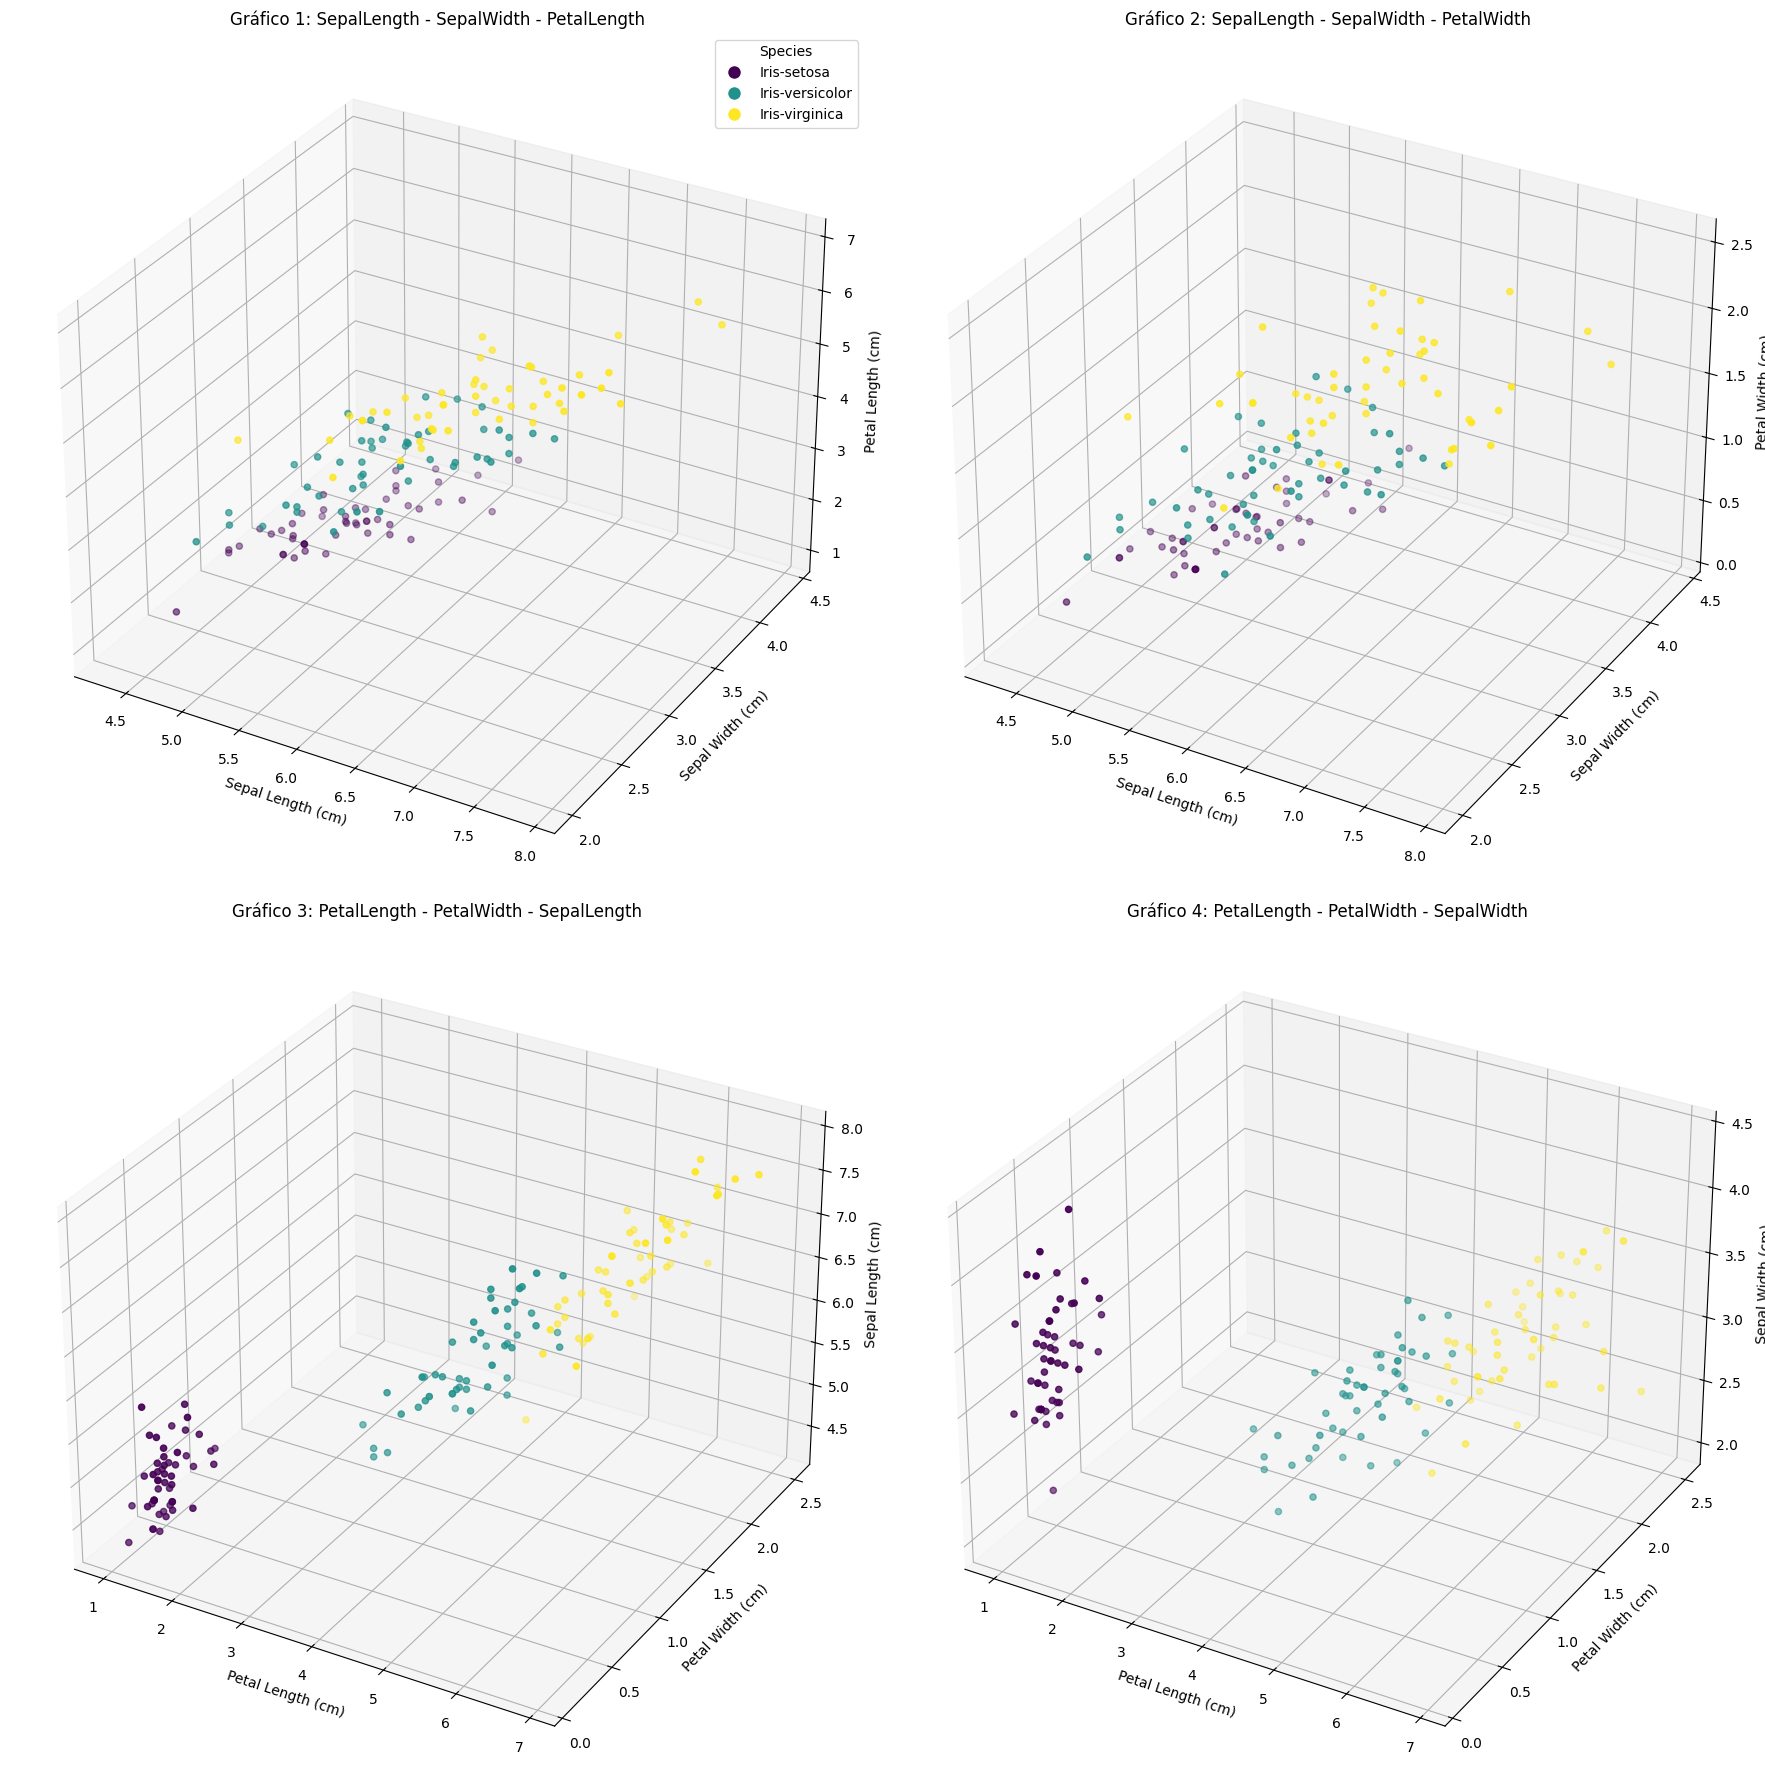

In [12]:
label_encoder = LabelEncoder()
iris['Species_encoded'] = label_encoder.fit_transform(iris['Species'])

fig = plt.figure(figsize=(18, 18))

ax1 = fig.add_subplot(2, 2, 1, projection='3d')
ax1.scatter(iris['SepalLengthCm'], iris['SepalWidthCm'], iris['PetalLengthCm'],
            c=iris['Species_encoded'], cmap='viridis', marker='o')
ax1.set_xlabel('Sepal Length (cm)')
ax1.set_ylabel('Sepal Width (cm)')
ax1.set_zlabel('Petal Length (cm)')
ax1.set_title('Gráfico 1: SepalLength - SepalWidth - PetalLength')

species_labels = [plt.Line2D([0], [0], marker='o', color='w',
                             markerfacecolor=plt.cm.viridis(i / 2), markersize=10)
                  for i in range(3)]
ax1.legend(species_labels, label_encoder.classes_, title="Species")

ax2 = fig.add_subplot(2, 2, 2, projection='3d')
ax2.scatter(iris['SepalLengthCm'], iris['SepalWidthCm'], iris['PetalWidthCm'],
            c=iris['Species_encoded'], cmap='viridis', marker='o')
ax2.set_xlabel('Sepal Length (cm)')
ax2.set_ylabel('Sepal Width (cm)')
ax2.set_zlabel('Petal Width (cm)')
ax2.set_title('Gráfico 2: SepalLength - SepalWidth - PetalWidth')

ax3 = fig.add_subplot(2, 2, 3, projection='3d')
ax3.scatter(iris['PetalLengthCm'], iris['PetalWidthCm'], iris['SepalLengthCm'],
            c=iris['Species_encoded'], cmap='viridis', marker='o')
ax3.set_xlabel('Petal Length (cm)')
ax3.set_ylabel('Petal Width (cm)')
ax3.set_zlabel('Sepal Length (cm)')
ax3.set_title('Gráfico 3: PetalLength - PetalWidth - SepalLength')

ax4 = fig.add_subplot(2, 2, 4, projection='3d')
ax4.scatter(iris['PetalLengthCm'], iris['PetalWidthCm'], iris['SepalWidthCm'],
            c=iris['Species_encoded'], cmap='viridis', marker='o')
ax4.set_xlabel('Petal Length (cm)')
ax4.set_ylabel('Petal Width (cm)')
ax4.set_zlabel('Sepal Width (cm)')
ax4.set_title('Gráfico 4: PetalLength - PetalWidth - SepalWidth')

plt.tight_layout()
plt.show()

In [13]:
iris.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   SepalLengthCm    150 non-null    float64
 1   SepalWidthCm     150 non-null    float64
 2   PetalLengthCm    150 non-null    float64
 3   PetalWidthCm     150 non-null    float64
 4   Species          150 non-null    object 
 5   Species_encoded  150 non-null    int64  
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


In [15]:
iris.describe()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species_encoded
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667,1.000000
std,0.828066,0.433594,1.764420,0.763161,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [16]:
iris.drop(columns=["Species"], inplace=True)
X = iris.drop(columns=["Species_encoded"])
y = iris["Species_encoded"]

In [18]:
y.describe()

,Species_encoded
count,150.000000
mean,1.000000
std,0.819232
min,0.000000
25%,0.000000
50%,1.000000
75%,2.000000
max,2.000000


In [19]:
print(iris['Species_encoded'].value_counts())

Species_encoded
0    50
1    50
2    50
Name: count, dtype: int64


In [22]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

knn = KNeighborsClassifier(n_neighbors=3)

knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)


In [23]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy * 100:.2f}%")

print("Classification Report:\n", classification_report(y_test, y_pred))

Accuracy: 100.00%
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [47]:
random_index = np.random.choice(X_test.index)
random_data = X_test.loc[random_index]

predicted_class = knn.predict([random_data])[0]

real_class_encoded = iris.loc[iris.index == random_index, "Species_encoded"].values[0]

real_class_name = label_encoder.inverse_transform([real_class_encoded])[0]

predicted_class_name = label_encoder.inverse_transform([predicted_class])[0]

print(f"Índice del dato aleatorio: {random_index}")
print(f"Dato seleccionado:\n{random_data}")
print(f"Clase real (codificada): {real_class_encoded}")
print(f"Clase real: {real_class_name}")
print(f"Clase predicha: {predicted_class_name}")

Índice del dato aleatorio: 18
Dato seleccionado:
SepalLengthCm    5.7
SepalWidthCm     3.8
PetalLengthCm    1.7
PetalWidthCm     0.3
Name: 18, dtype: float64
Clase real (codificada): 0
Clase real: Iris-setosa
Clase predicha: Iris-setosa


/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


In [ ]:
import pandas as pd

# Cargar el CSV original
df = pd.read_csv("/content/Lista productos Xico.csv")

df.head()

,Presentación (gr),Nombre del Producto
0,1000,BOLA DE CERVEZA XICO
1,1000,CHARLOTTE SALCHICHA DE POLLO JUMBO KG
2,1000,CHORIZO AHUMADO ESPAÑOL
3,1000,CHORIZO ARGENTINO
4,1000,CHORIZO DE CERDO XICO


In [ ]:
# Función para clasificar el tipo de producto
def clasificar_tipo(nombre):
    nombre_upper = nombre.upper()
    if "SALCHICHA" in nombre_upper:
        return "Salchicha"
    if "MORTADELA" in nombre_upper:
        return "Mortadela"
    if "QUESO" in nombre_upper:
        return "Queso"
    if "TOCINO" in nombre_upper:
        return "Tocino"
    elif any(palabra in nombre_upper for palabra in ["LONGANIZA", "CHORIZO"]):
        return "Chorizo"
    elif any(palabra in nombre_upper for palabra in ["JAMON", "JAMÓN"]):
        return "Jamón"
    elif "SALCHICHÓN" in nombre_upper:
        return "Salchichón"
    elif "SALAMI" in nombre_upper:
        return "Salami"
    elif "PEPERONI" in nombre_upper:
        return "Peperoni"
    elif any(palabra in nombre_upper for palabra in ["CUERO", "CUEROS", "CUERITOS"]):
        return "Cueros"
    elif any(palabra in nombre_upper for palabra in ["CHULETA", "LOMO", "BISTEC", "MILANESA", "CARNE", "COSTILLA", "PIERNA"]):
        return "Carne"
    else:
        return "Otro"

# Crear la columna 'Tipo'
df["Tipo"] = df["Nombre del Producto"].apply(clasificar_tipo)

# Guardar en un nuevo archivo CSV codificado en UTF-8 sin BOM
# Guardar el CSV con codificación latin1 (ISO-8859-1)
df.to_csv("productos_clasificados3.csv", index=False, encoding="latin1")
